# Chennai SmartBike — exploration

In [2]:
import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt

DATA = os.environ.get("CHENNAI_DATA", "../../GNN-TRANSPORTATION/aadarsh-bikeshare/chennai")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#999999"

key = lambda s: re.sub(r"[^a-z0-9]+", " ", str(s).lower().replace("\u2013", "-")).strip()

df = pd.read_excel(f"{DATA}/bikesharing2.xlsx", sheet_name="tripdata")
df = df.drop_duplicates().dropna(subset=["pickup_station", "drop_station"])
df = df[df.vehicle_type != "SmartBike"]
df["t"] = pd.to_datetime(df.ride_start_time)
df["o"] = df.pickup_station.map(key)
df["d"] = df.drop_station.map(key)
bad = df.o.str.contains("amma arangam|test") | df.d.str.contains("amma arangam|test")
df = df[~bad]                                             # operator depot / test entries
df["loop"] = df.o == df.d
df["hour"] = df.t.dt.hour
df["weekend"] = df.t.dt.dayofweek >= 5
df["month"] = df.t.dt.to_period("M")

st = pd.read_excel(f"{DATA}/bikesharing2.xlsx", sheet_name="109 live stations")
st.columns = [x.strip() for x in st.columns]
st = st.dropna(subset=["Station Name"]).copy()
st["o"] = st["Station Name"].map(key)
st.loc[st.Latitude > 90, "Latitude"] /= 1e6
st = st.drop_duplicates("o").set_index("o")[["Latitude", "Longitude"]]

print(len(df), "rides |", df.o.nunique(), "stations |", df.t.min().date(), "→", df.t.max().date())

197184 rides | 113 stations | 2021-01-22 → 2022-08-29


## 1. The day has no commute peak

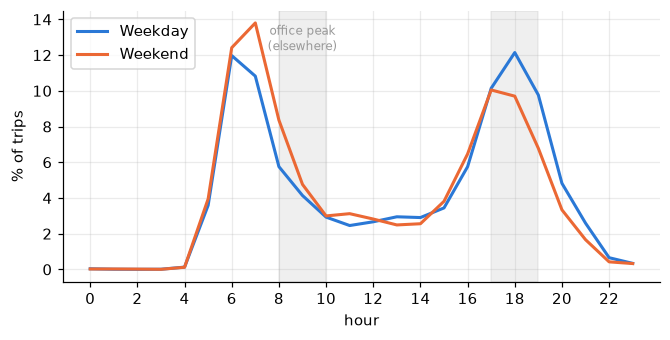

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for m, lab, col in [(~df.weekend, "Weekday", BLUE), (df.weekend, "Weekend", ORANGE)]:
    s = df[m].hour.value_counts(normalize=True).sort_index() * 100
    ax.plot(s.index, s.values, lw=2, color=col, label=lab)
ax.axvspan(8, 10, color=GREY, alpha=.15)
ax.axvspan(17, 19, color=GREY, alpha=.15)
ax.text(9, ax.get_ylim()[1]*.95, "office peak\n(elsewhere)", ha="center", va="top", fontsize=8, color=GREY)
ax.set(xlabel="hour", ylabel="% of trips", xticks=range(0, 24, 2))
ax.legend()
plt.show()

## 2. Two thirds of rides go nowhere

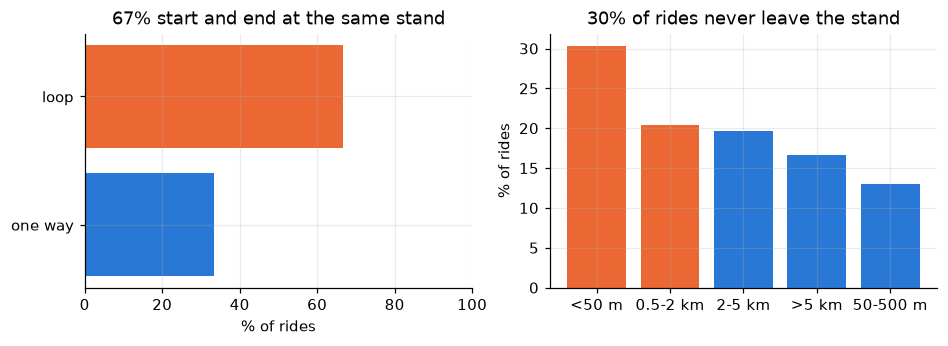

In [4]:
loop = df.loop.mean() * 100
short = (df.distance_covered <= .05).mean() * 100
bands = pd.cut(df.distance_covered, [-1, .05, .5, 2, 5, 1e9],
               labels=["<50 m", "50-500 m", "0.5-2 km", "2-5 km", ">5 km"]).value_counts(normalize=True) * 100

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].barh(["one way", "loop"], [100 - loop, loop], color=[BLUE, ORANGE])
ax[0].set(xlim=(0, 100), xlabel="% of rides", title=f"{loop:.0f}% start and end at the same stand")
ax[1].bar(bands.index.astype(str), bands.values, color=[ORANGE, ORANGE, BLUE, BLUE, BLUE])
ax[1].set(ylabel="% of rides", title=f"{short:.0f}% of rides never leave the stand")
plt.show()

## 3. Raw demand is mostly station age

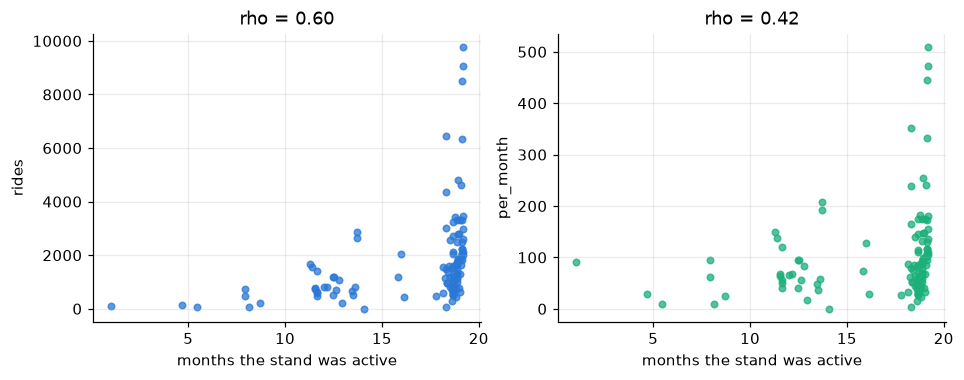

                                                 rides  months  per_month
o                                                                        
marina beach avvaiyar statue                      9782    19.2      509.9
marina beach near lighthouse                      9081    19.2      473.3
marina beach water kiosk                          8498    19.1      444.5
mannady metro                                     6463    18.3      352.6
marina beach swimming pool                        6347    19.2      331.4
anna nagar 18th main road                         4819    18.9      254.7
bouganvillea park anna nagar east feeder          4609    19.1      241.5
lakshmi nagar e seva childrens park nanganallur   4363    18.3      238.0


In [5]:
g = df.groupby("o").t
sta = pd.DataFrame({"rides": df.groupby("o").size(),
                    "first": g.min(), "last": g.max()})
sta["months"] = ((sta["last"] - sta["first"]).dt.days / 30.44).clip(lower=1)
sta["per_month"] = sta.rides / sta.months

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharex=True)
for a, col, c_ in zip(ax, ["rides", "per_month"], [BLUE, GREEN]):
    a.scatter(sta.months, sta[col], s=18, color=c_, alpha=.75)
    r = sta[["months", col]].corr("spearman").iloc[0, 1]
    a.set(xlabel="months the stand was active", ylabel=col, title=f"rho = {r:.2f}")
plt.show()

print(sta.sort_values("per_month", ascending=False).head(8)[["rides", "months", "per_month"]].round(1))

## 4. Flows fall off with distance

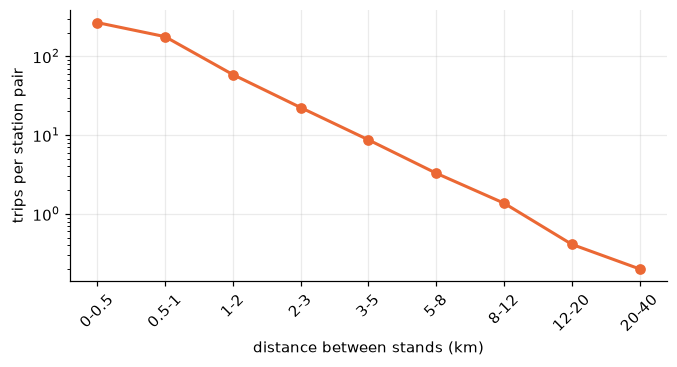

In [6]:
nodes = sorted(set(df.o) | set(df.d))
ix = {k: i for i, k in enumerate(nodes)}
xy = st.reindex(nodes)
lat, lon = xy.Latitude.values, xy.Longitude.values

R = 6371000
p = np.radians(np.c_[lat, lon])
dlat = p[:, None, 0] - p[None, :, 0]
dlon = p[:, None, 1] - p[None, :, 1]
a = np.sin(dlat/2)**2 + np.cos(p[:, None, 0]) * np.cos(p[None, :, 0]) * np.sin(dlon/2)**2
DIST = 2 * R * np.arcsin(np.sqrt(a)) / 1000                       # km

A = np.zeros((len(nodes), len(nodes)))
for o, d, w in df[~df.loop].groupby(["o", "d"]).size().reset_index(name="w").values:
    A[ix[o], ix[d]] = w

edges = np.isfinite(DIST) & np.triu(np.ones_like(DIST), 1).astype(bool)
bins = np.array([0, .5, 1, 2, 3, 5, 8, 12, 20, 40])
lab = [f"{bins[i]:g}-{bins[i+1]:g}" for i in range(len(bins) - 1)]
trips_b, pairs_b = [], []
for i in range(len(lab)):
    m = edges & (DIST >= bins[i]) & (DIST < bins[i+1])
    trips_b.append((A + A.T)[m].sum())
    pairs_b.append(m.sum())
rate = np.array(trips_b) / np.maximum(pairs_b, 1)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(lab, rate, "o-", color=ORANGE, lw=2)
ax.set(yscale="log", xlabel="distance between stands (km)", ylabel="trips per station pair")
plt.xticks(rotation=45)
plt.show()

## 5. Neighbouring stations resemble each other — the case for a graph

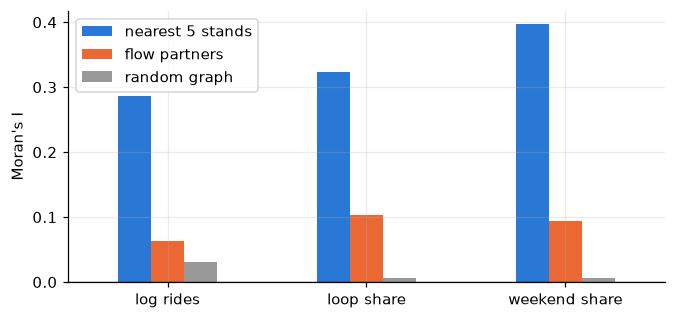

               nearest 5 stands  flow partners  random graph
log rides                 0.002          0.112         0.492
loop share                0.002          0.014         0.882
weekend share             0.002          0.038         0.896


In [7]:
def rownorm(W):
    W = W.copy(); np.fill_diagonal(W, 0)
    s = W.sum(1, keepdims=True); s[s == 0] = 1
    return W / s

K = 5
A_space = np.zeros_like(A)
for i in range(len(nodes)):
    if np.isfinite(DIST[i]).any():
        for j in np.argsort(np.where(np.isnan(DIST[i]), np.inf, DIST[i]))[1:K+1]:
            if np.isfinite(DIST[i, j]):
                A_space[i, j] = A_space[j, i] = 1

rng = np.random.default_rng(0)
W = {"nearest 5 stands": rownorm(A_space),
     "flow partners":    rownorm(A + A.T),
     "random graph":     rownorm((rng.random(A.shape) < A_space.mean()).astype(float))}

def moran(x, Wm, n=499):
    keep = Wm.sum(1) > 0
    z = x[keep] - x[keep].mean()
    Wk = rownorm(Wm[np.ix_(keep, keep)])
    I = len(z) / Wk.sum() * (z @ Wk @ z) / (z**2).sum()
    null = [len(z) / Wk.sum() * (zp @ Wk @ zp) / (z**2).sum()
            for zp in (rng.permutation(z) for _ in range(n))]
    return I, (np.sum(np.abs(null) >= abs(I)) + 1) / (n + 1)

X = {"log rides":   np.log1p(df.groupby("o").size().reindex(nodes).fillna(0).values),
     "loop share":  df.groupby("o").loop.mean().reindex(nodes).fillna(0).values,
     "weekend share": df.groupby("o").weekend.mean().reindex(nodes).fillna(0).values}

out = {w: {x: moran(v, Wm) for x, v in X.items()} for w, Wm in W.items()}
res  = pd.DataFrame({w: {x: v[0] for x, v in d.items()} for w, d in out.items()})
pval = pd.DataFrame({w: {x: v[1] for x, v in d.items()} for w, d in out.items()})

fig, ax = plt.subplots(figsize=(7, 3.2))
res.plot.bar(ax=ax, color=[BLUE, ORANGE, GREY], rot=0)
ax.axhline(0, color="k", lw=.8)
ax.set(ylabel="Moran's I")
plt.show()
print(pval.round(3))

## 6. Stations split into four usage types

/var/folders/mc/y37523q95h93zmdcvkvcrtl80000gn/T/ipykernel_38577/3620214936.py:3: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  P = P[P.sum(1) >= 200]
/var/folders/mc/y37523q95h93zmdcvkvcrtl80000gn/T/ipykernel_38577/3620214936.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  Z = P.div(P.sum(1), axis=0).values
/var/folders/mc/y37523q95h93zmdcvkvcrtl80000gn/T/ipykernel_38577/3620214936.py:16: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  top = P.index[lab == i][np.argmax(P.sum(1)[lab == i].values)]
/var/folders/mc/y37523q95h93zmdcvkvcrtl80000gn/T/ipykernel_38577/3620214936.py:16: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  top = P.index[lab == i][np.argmax(P.sum(1)[lab == i].values)]
/var/folders/mc/y37523q95h93zmdcvkvcrtl80000gn/T/ipykernel_38577/3620214936.py:16: Pandas4Warning: Starting with

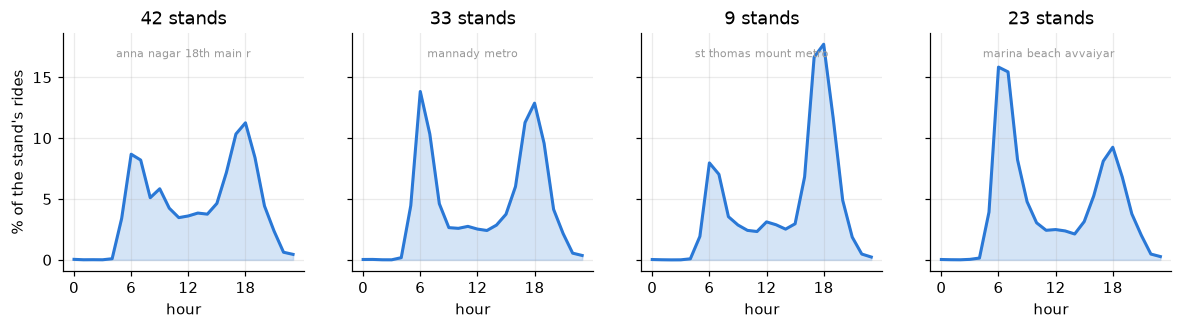

In [8]:
P = (df.pivot_table(index="o", columns="hour", values="user_id", aggfunc="size")
       .reindex(columns=range(24)).fillna(0))
P = P[P.sum(1) >= 200]
Z = P.div(P.sum(1), axis=0).values

k, rng = 4, np.random.default_rng(0)
cent = Z[rng.choice(len(Z), k, replace=False)]
for _ in range(50):
    lab = np.argmin(((Z[:, None] - cent)**2).sum(-1), 1)
    cent = np.array([Z[lab == i].mean(0) if (lab == i).any() else cent[i] for i in range(k)])

fig, ax = plt.subplots(1, k, figsize=(13, 2.8), sharey=True)
for i in range(k):
    ax[i].fill_between(range(24), Z[lab == i].mean(0) * 100, alpha=.2, color=BLUE)
    ax[i].plot(range(24), Z[lab == i].mean(0) * 100, lw=2, color=BLUE)
    top = P.index[lab == i][np.argmax(P.sum(1)[lab == i].values)]
    ax[i].set(title=f"{(lab == i).sum()} stands", xlabel="hour", xticks=range(0, 24, 6))
    ax[i].text(.5, .9, top[:22], transform=ax[i].transAxes, ha="center", fontsize=7, color=GREY)
ax[0].set_ylabel("% of the stand's rides")
plt.show()

## 7. Season changes how far people ride, not when

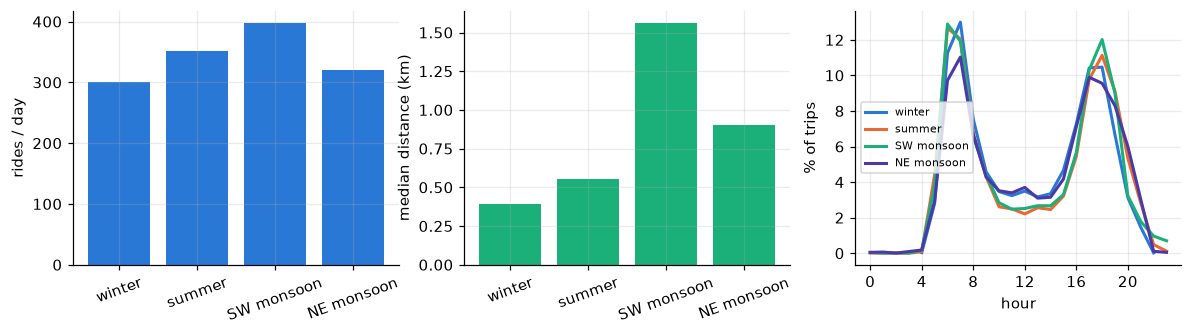

season   winter   summer  SW monsoon  NE monsoon
t                                               
2021    10983.0  24956.0     52834.0     26910.0
2022    17630.0  35104.0     28767.0         NaN


In [9]:
# IMD seasons: winter Jan-Feb, summer Mar-May, SW monsoon Jun-Sep, NE monsoon Oct-Dec
# https://mausam.imd.gov.in/chennai/mcdata/ne_monsoon_2022.pdf
season = {1:"winter",2:"winter",3:"summer",4:"summer",5:"summer",
          6:"SW monsoon",7:"SW monsoon",8:"SW monsoon",9:"SW monsoon",
          10:"NE monsoon",11:"NE monsoon",12:"NE monsoon"}
order = ["winter", "summer", "SW monsoon", "NE monsoon"]
df["season"] = df.t.dt.month.map(season)

per_day = df.groupby(["season", df.t.dt.date]).size().groupby("season").mean().reindex(order)
dist = df.groupby("season").distance_covered.median().reindex(order)

fig, ax = plt.subplots(1, 3, figsize=(13, 3))
ax[0].bar(order, per_day.values, color=BLUE); ax[0].set(ylabel="rides / day")
ax[1].bar(order, dist.values, color=GREEN);   ax[1].set(ylabel="median distance (km)")
for s, col in zip(order, [BLUE, ORANGE, GREEN, "#4a3aa7"]):
    v = df[df.season == s].hour.value_counts(normalize=True).sort_index() * 100
    ax[2].plot(v.index, v.values, lw=2, color=col, label=s)
ax[2].set(xlabel="hour", ylabel="% of trips", xticks=range(0, 24, 4)); ax[2].legend(fontsize=7)
for a in ax[:2]: a.tick_params(axis="x", rotation=20)
plt.show()

print(df.groupby([df.t.dt.year, "season"]).size().unstack().reindex(columns=order))